In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import random
from timeit import default_timer as timer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor
from scipy.stats import randint as sp_randint
from scipy.stats import loguniform as sp_loguniform
from skopt.space import Integer, Real
from skopt import BayesSearchCV
from helper import *
from plots import *

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

In [4]:
df = pd.read_csv("diamonds.csv")

## 1. Предобработка

In [5]:
df_preprocessed = df.copy()
df_preprocessed = df_preprocessed.drop(columns=['Unnamed: 0'])

X, y = divide_data(df_preprocessed, 'price')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

categorical_cols = ['cut', 'color', 'clarity']
category_orders = [
    ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],          # cut
    ['J', 'I', 'H', 'G', 'F', 'E', 'D'],                        # color
    ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'],   # clarity
]

preprocessor = ColumnTransformer(
    [('encoder', OrdinalEncoder(categories=category_orders), categorical_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
)
preprocessor.set_output(transform="pandas")

,transformers,"[('encoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,categories,"[['Fair', 'Good', ...], ['J', 'I', ...], ...]"
,dtype,<class 'numpy.float64'>
,handle_unknown,'error'


In [6]:
base_model = ('LGBMRegressor', LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1))

In [7]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    base_model
])

In [ ]:
initial_metrics = train_evaluate_models_regression(
    models=[('LGBMRegressor', pipeline)],
    X_train=X_train, 
    y_train=y_train,
    X_test=X_test, 
    y_test=y_test
)

In [10]:
initial_metrics

,MAE,RMSE,R2,"MAPE, %"
LGBMRegressor,276.456459,530.892193,0.98227,8.058122


## 2. Подбор гиперпараметров

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

### 2.1 Grid Search

In [ ]:
param_grid = {
    "LGBMRegressor__num_leaves": [31, 63, 127],        # максимальное количество листьев в дереве
    "LGBMRegressor__max_depth": [7, 10, -1],           # максимальная глубина (-1 = без ограничения)
    "LGBMRegressor__min_child_samples": [10, 20, 40],  # минимум объектов в листе (контроль переобучения)

    "LGBMRegressor__learning_rate": [0.05, 0.1],       # шаг градиентного спуска
    "LGBMRegressor__n_estimators": [200, 500, 1000],   # количество деревьев в ансамбле
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=3
)

In [13]:
grid_search_start = timer()
grid_search.fit(X_train, y_train)
grid_search_end = timer()

print(f"Total time: {grid_search_end - grid_search_start:.2f} seconds")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Total time: 376.81 seconds


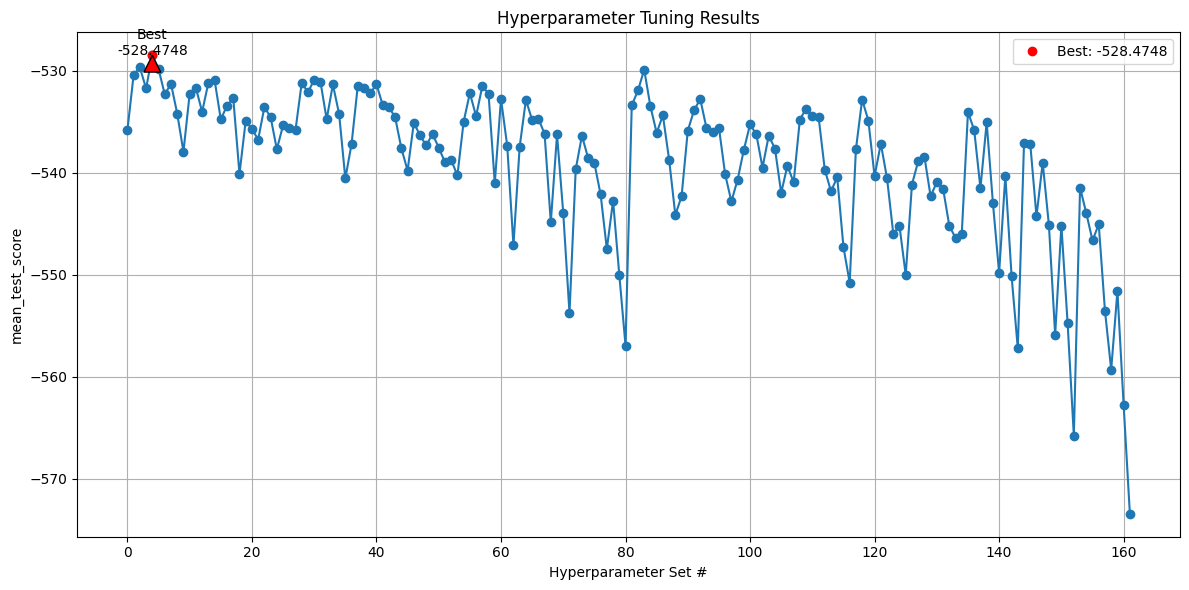

In [14]:
data = plot_hyperparam_search_results(grid_search.cv_results_, xtick_step=20)

In [15]:
grid_search.best_params_

{'LGBMRegressor__learning_rate': 0.05,
 'LGBMRegressor__max_depth': 7,
 'LGBMRegressor__min_child_samples': 10,
 'LGBMRegressor__n_estimators': 500,
 'LGBMRegressor__num_leaves': 63}

In [ ]:
grid_search_metrics = train_evaluate_models_regression(
    models=[('LGBMRegressor', grid_search.best_estimator_)],
    X_train=X_train, 
    y_train=y_train,
    X_test=X_test, 
    y_test=y_test
)

In [17]:
grid_search_metrics

,MAE,RMSE,R2,"MAPE, %"
LGBMRegressor,264.084858,526.997823,0.982529,6.784867


(<Figure size 800x400 with 1 Axes>,
                     MAE      RMSE        R2    MAPE, %
 LGBMRegressor  4.475063  0.733552  0.026384  15.800895)

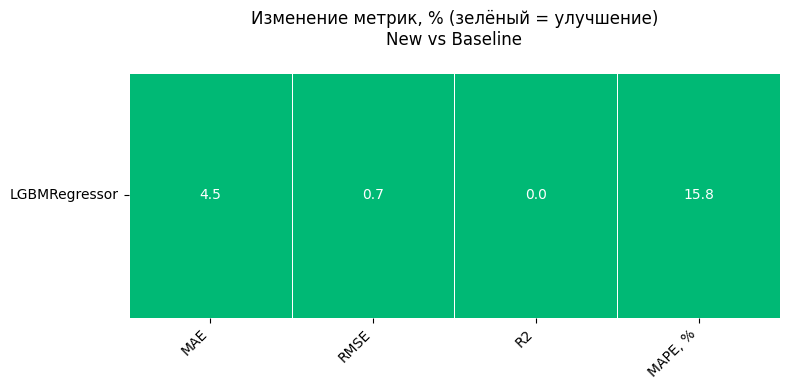

In [18]:
compare_regression_metrics_heatmap(initial_metrics, grid_search_metrics)

### 2.2 Randomized search

In [63]:
param_dist = {
    "LGBMRegressor__num_leaves": sp_randint(15, 256),
    "LGBMRegressor__max_depth": sp_randint(5, 16),
    "LGBMRegressor__min_child_samples": sp_randint(5, 50),

    "LGBMRegressor__learning_rate": sp_loguniform(0.01, 0.3),
    "LGBMRegressor__n_estimators": sp_randint(100, 1500),
}

randomized_search = RandomizedSearchCV(
    random_state=SEED,
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=100,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=3
)

In [64]:
randomized_search_start = timer()
randomized_search.fit(X_train, y_train)
randomized_search_end = timer()

print(f"Total time: {randomized_search_end - randomized_search_start:.2f} seconds")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Total time: 347.78 seconds


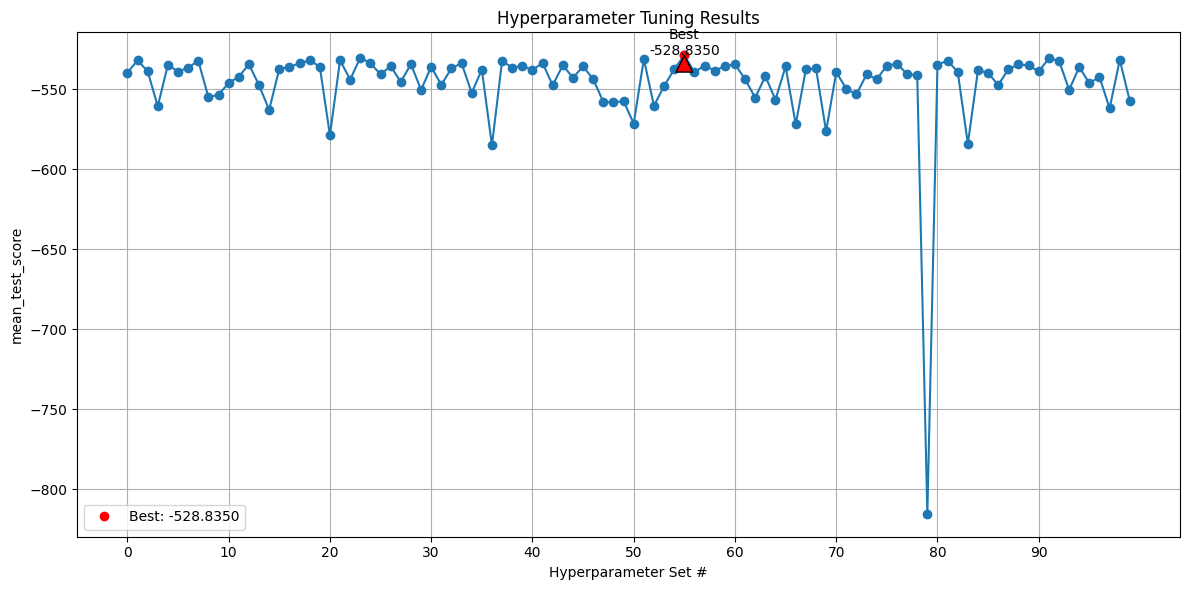

In [65]:
data = plot_hyperparam_search_results(randomized_search.cv_results_, xtick_step=10)

In [66]:
randomized_search.best_params_

{'LGBMRegressor__learning_rate': np.float64(0.026265502046199228),
 'LGBMRegressor__max_depth': 6,
 'LGBMRegressor__min_child_samples': 6,
 'LGBMRegressor__n_estimators': 921,
 'LGBMRegressor__num_leaves': 177}

In [ ]:
randomized_search_metrics = train_evaluate_models_regression(
    models=[('LGBMRegressor', randomized_search.best_estimator_)],
    X_train=X_train, 
    y_train=y_train,
    X_test=X_test, 
    y_test=y_test
)

(<Figure size 800x400 with 1 Axes>,
                    MAE      RMSE        R2    MAPE, %
 LGBMRegressor  5.01458  1.265898  0.045409  15.888018)

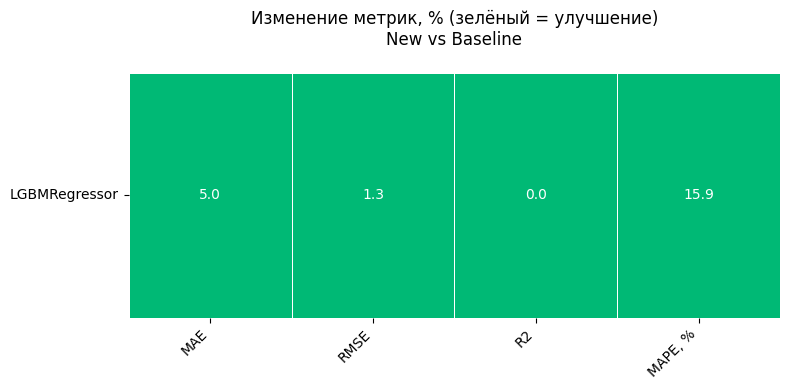

In [68]:
compare_regression_metrics_heatmap(initial_metrics, randomized_search_metrics)

### 2.3 Bayes Search

In [69]:
param_bayes = {
    "LGBMRegressor__num_leaves": Integer(15, 255),
    "LGBMRegressor__max_depth": Integer(5, 15),
    "LGBMRegressor__min_child_samples": Integer(5, 50),
    "LGBMRegressor__learning_rate": Real(0.01, 0.3, prior='log-uniform'),

    "LGBMRegressor__n_estimators": Integer(100, 1500),

}

bayes_search = BayesSearchCV(
    random_state=SEED,
    estimator=pipeline,
    search_spaces=param_bayes,
    n_iter=50,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    optimizer_kwargs={'base_estimator': 'GP'},
    verbose=3,
    n_jobs=-1
)

In [70]:
bayes_search_start = timer()
bayes_search.fit(X_train, y_train)
bayes_search_end = timer()

print(f"Total time: {bayes_search_end - bayes_search_start:.2f} seconds")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

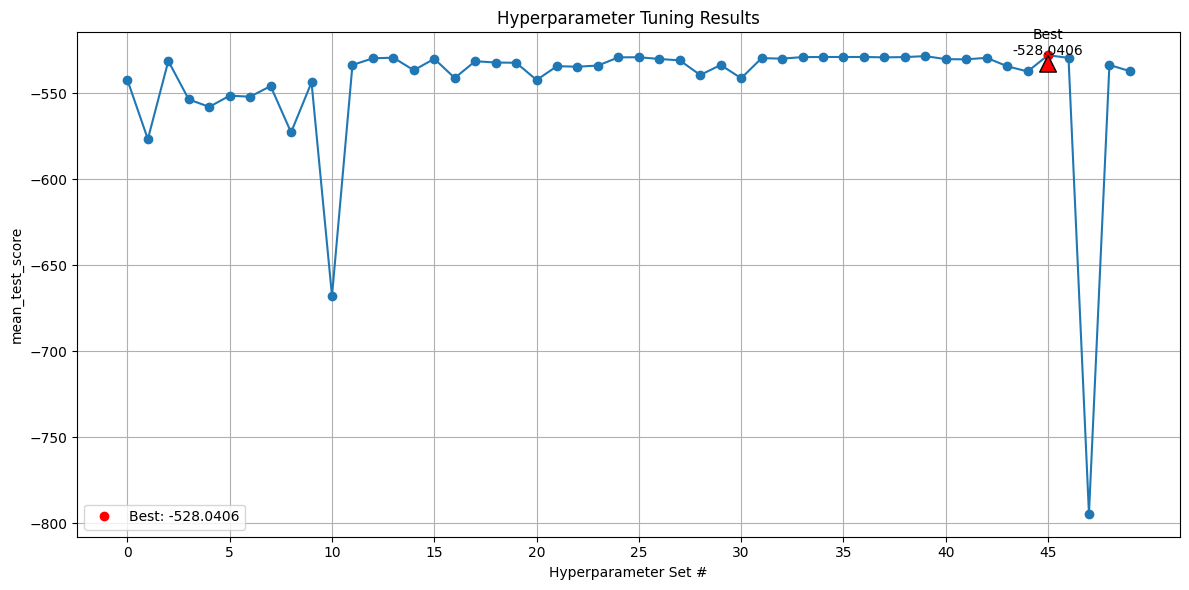

In [71]:
data = plot_hyperparam_search_results(bayes_search.cv_results_, xtick_step=5)


In [72]:
bayes_search.best_params_

OrderedDict([('LGBMRegressor__learning_rate', 0.037245767428504384),
             ('LGBMRegressor__max_depth', 15),
             ('LGBMRegressor__min_child_samples', 5),
             ('LGBMRegressor__n_estimators', 970),
             ('LGBMRegressor__num_leaves', 37)])

In [ ]:
bayes_search_metrics = train_evaluate_models_regression(
    models=[('LGBMRegressor', bayes_search.best_estimator_)],
    X_train=X_train, 
    y_train=y_train,
    X_test=X_test, 
    y_test=y_test
)

In [74]:
bayes_search_metrics

,MAE,RMSE,R2,"MAPE, %"
LGBMRegressor,263.632292,526.134473,0.982587,6.745589


(<Figure size 800x400 with 1 Axes>,
                     MAE      RMSE        R2    MAPE, %
 LGBMRegressor  4.638766  0.896174  0.032206  16.288329)

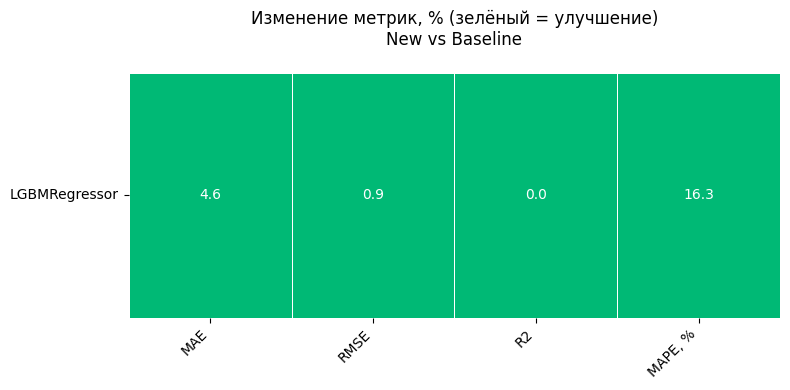

In [75]:
compare_regression_metrics_heatmap(initial_metrics, bayes_search_metrics)

# Итоговое сравнение 

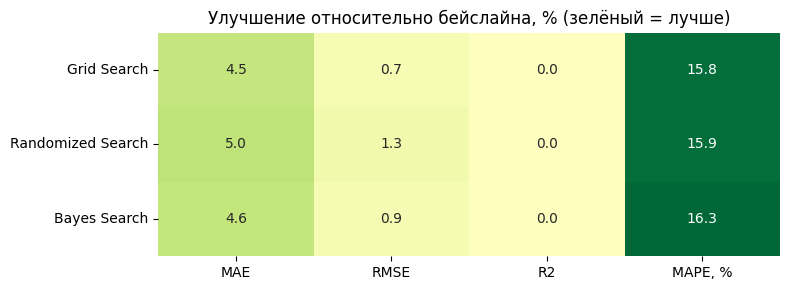

In [ ]:
lower_is_better = ['MAE', 'RMSE', 'MAPE, %']

deltas = []
for name, m in [('Grid Search', grid_search_metrics),
                ('Randomized Search', randomized_search_metrics),
                ('Bayes Search', bayes_search_metrics)]:
    d = (m - initial_metrics) / initial_metrics.abs() * 100
    d[lower_is_better] = -d[lower_is_better]  
    deltas.append(d.rename(index={'LGBMRegressor': name}))
deltas = pd.concat(deltas)

plt.figure(figsize=(8, 3))
sns.heatmap(deltas, annot=True, fmt='.1f', cmap='RdYlGn', center=0, cbar=False)
plt.title('Улучшение относительно бейслайна, % (зелёный = лучше)')
plt.tight_layout()
plt.show()

Подбор гиперпараметров улучшил все метрики относительно бейслайна для всех трёх методов.
Сильнее всего снизилась MAPE и MAE, RMSE улучшилась слабее, а R² практически не изменился, так как бейслайн уже объяснял ≈ 98% дисперсии.

In [77]:
for name, s in [('Grid Search', grid_search), ('Randomized Search', randomized_search), ('Bayes Search', bayes_search)]:
    i = s.best_index_
    print(f"{name:11s} {-s.cv_results_['mean_test_score'][i]:.2f} ± {s.cv_results_['std_test_score'][i]:.2f}")

Grid Search 528.47 ± 10.00
Randomized Search 528.83 ± 15.32
Bayes Search 528.04 ± 11.83


По кросс-валидационному RMSE лучшим формально оказался Bayes Search